In [4]:
from enum import Enum
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from statsmodels.distributions.empirical_distribution import ECDF

In [5]:

class Dist:
    def __init__(self, name, distribution, start, end):
        self.name = name
        self.distribution = distribution
        self.start = start
        self.end = end


class Rvs(Enum):
    NORMAL = Dist("нормального", stats.norm(loc=0, scale=1), start=-3, end=3)
    CHI = Dist("Хи-квадрат", stats.chi2(df=5), start=0, end=15)
    STUDENT = Dist("Стьюдента", stats.t(df=10), start=-4, end=4)
    FISHER = Dist("Фишера", stats.f(dfn=10, dfd=20), start=0, end=5)
    LAPLACE = Dist("Лапласа", stats.laplace(loc=0, scale=1), start=-5, end=5)
    COUCHY = Dist("Коши", stats.cauchy(loc=0, scale=1), start=-5, end=5)
    POISSON = Dist("Пуассона", stats.poisson(mu=3), start=0, end=10)

Переменная распределения

In [ ]:
rasp = Rvs.COUCHY.value

AttributeError: type object 'Rvs' has no attribute 'E'

Блок инициализации

In [ ]:
rv = rasp.distribution 
name = rasp.name
x1 = rasp.start
x2 = rasp.end
sample = rv.rvs(1000, random_state=1)  # выборка

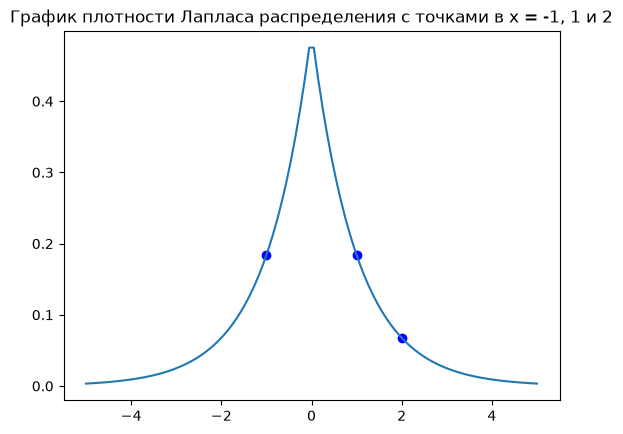

In [ ]:
# 1: картинка плотности распределения с точками -1, 1 и 2
x = np.linspace(x1, x2, 100)
pdf = rv.pdf(x)

plt.title(f"График плотности {name} распределения c точками в x = -1, 1 и 2")
plt.plot(x, pdf)
plt.scatter([-1, 1, 2], [rv.pdf(-1), rv.pdf(1), rv.pdf(2)], color="blue")

plt.show()

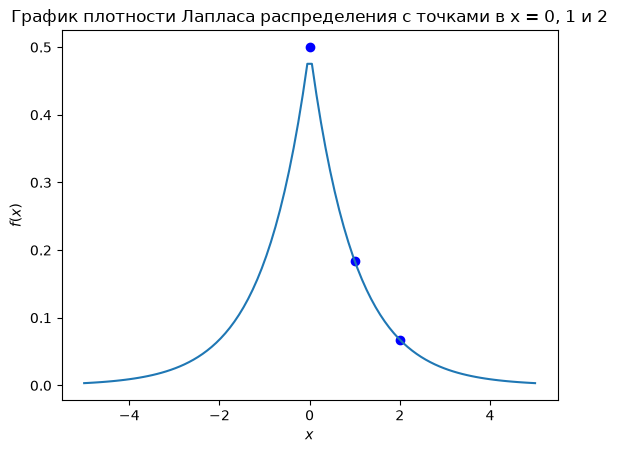

In [ ]:
# 2: график значения функции распределения с точками в x = 0, 1 и 2
plt.title(f"График плотности {name} распределения c точками в x = 0, 1 и 2")
plt.plot(x, pdf)
plt.ylabel("$f(x)$")
plt.xlabel("$x$")
plt.scatter([0, 1, 2], [rv.pdf(0), rv.pdf(1), rv.pdf(2)], color="blue")

plt.show()


In [ ]:
print(f"Значение функции {name} распределения в точке 1: {rv.cdf(1)}")


Значение функции Лапласа распределения в точке 1: 0.8160602794142788


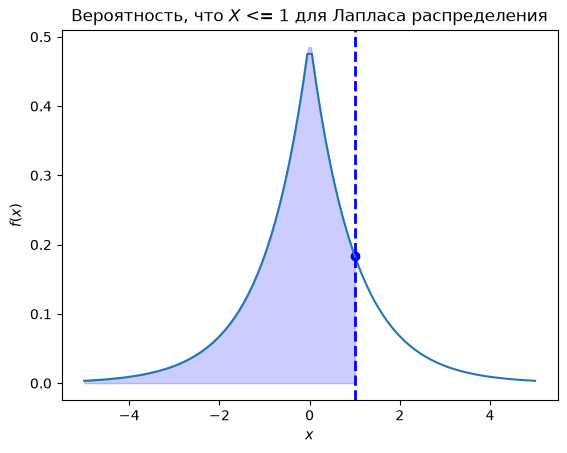

In [ ]:
# 3: вероятность, что X <= 1 на графике плотности распределения
x = np.linspace(x1, x2, 100)
pdf = rv.pdf(x)

plt.title(f"Вероятность, что $X$ <= 1 для {name} распределения")

plt.plot(x, pdf)
plt.ylabel("$f(x)$")
plt.xlabel("$x$")

plt.scatter([1], [rv.pdf(1)], color="blue")
xq = np.linspace(x1, 1, 100)
yq = rv.pdf(xq)
plt.fill_between(xq, 0, yq, color="blue", alpha=0.2)

plt.axvline(1, color="blue", linestyle="--", lw=2);

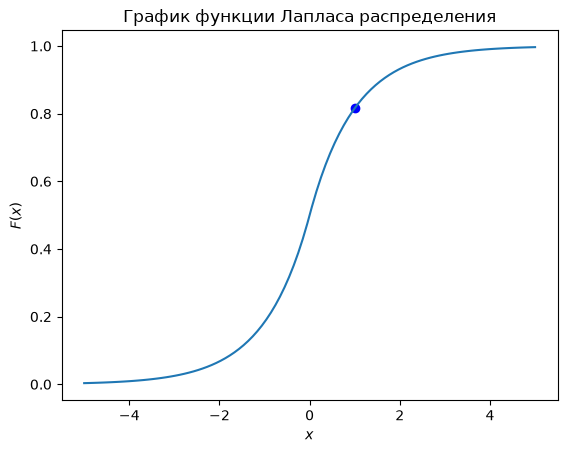

In [ ]:
# 4: построение графика функции распределения
x = np.linspace(x1, x2, 100)
cdf = rv.cdf(x)

plt.title(f"График функции {name} распределения")
plt.plot(x, cdf)
plt.ylabel("$F(x)$")
plt.xlabel("$x$")

plt.scatter([1], [rv.cdf(1)], color="blue");

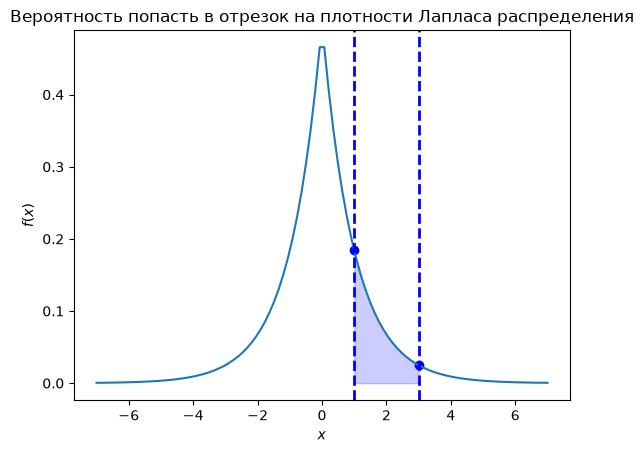

In [ ]:

# 5. График вероятности попасть в конкретный отрезок на плотности распределения
x = np.linspace(x1-2, x2+2, 100)
pdf = rv.pdf(x)

plt.title(f"Вероятность попасть в отрезок на плотности {name} распределения")
plt.plot(x, pdf)
plt.ylabel("$f(x)$")
plt.xlabel("$x$")

# На ней же нарисуем f(1)
plt.scatter([1, 3], [rv.pdf(1), rv.pdf(3)], color="blue")

# на ту же картинку добавили новую часть, штриховку
xq = np.linspace(1, 3)
yq = rv.pdf(xq)
plt.fill_between(xq, 0, yq, color="blue", alpha=0.2)

plt.axvline(1, color="blue", linestyle="--", lw=2)
plt.axvline(3, color="blue", linestyle="--", lw=2)

plt.show()

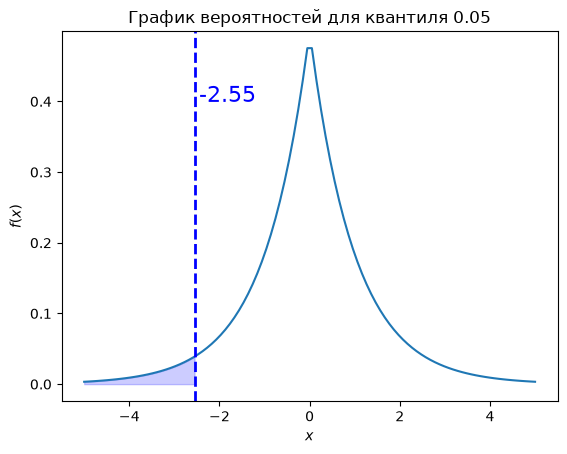

In [ ]:

# 6. Изображаем квантили
x = np.linspace(x1, x2, 100)
pdf = rv.pdf(x)

quantile = 0.05

np_q = np.quantile(sample, quantile)

plt.title(f"График вероятностей для квантиля {quantile}")
plt.plot(x, pdf)
plt.ylabel("$f(x)$")
plt.xlabel("$x$")

xq = np.linspace(x1, np_q)
yq = rv.pdf(xq)
plt.fill_between(xq, 0, yq, color="blue", alpha=0.2)

plt.axvline(np_q, color="blue", linestyle="--", lw=2)

y_max = plt.ylim()[1]
plt.text(np_q + 0.1, 0.8 * y_max, round(np_q, 2), color="blue", fontsize=16)
plt.show()



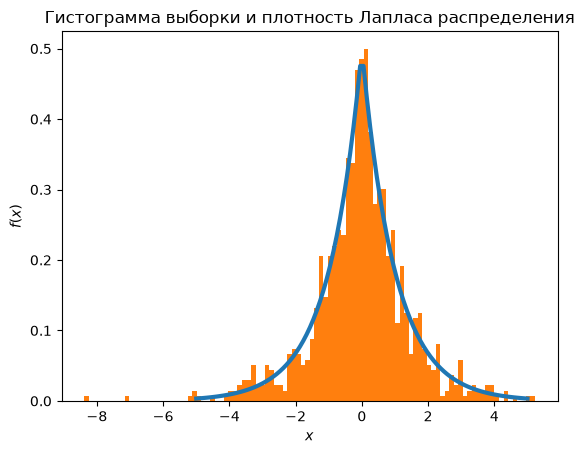

In [ ]:

x = np.linspace(x1, x2, 100)
pdf = rv.pdf(x)

plt.plot(x, pdf, lw=3)
plt.title(f"Гистограмма выборки и плотность {name} распределения")

# гистограмма, параметр density отнормировал её.
plt.hist(sample, bins=100, density=True)

plt.ylabel("$f(x)$")
plt.xlabel("$x$")
plt.show()

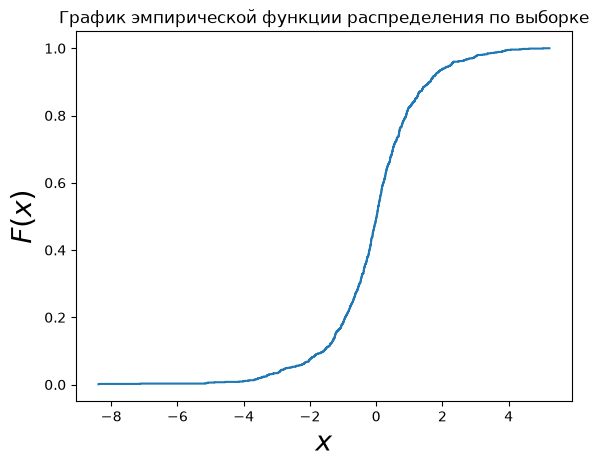

In [ ]:

ecdf = ECDF(sample)
plt.title(f"График эмпирической функции распределения по выборке")
plt.step(ecdf.x, ecdf.y)
plt.ylabel('$F(x)$', fontsize=20)
plt.xlabel('$x$', fontsize=20);

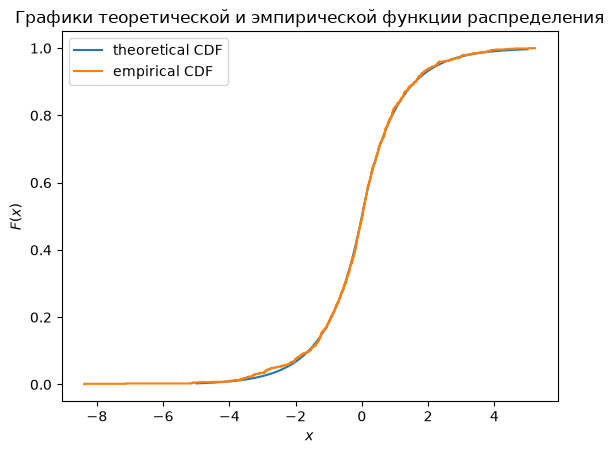

In [ ]:
x = np.linspace(x1, x2, 100)

plt.title(f"Графики теоретической и эмпирической функции распределения")

# теоретическа cdf 
cdf = rv.cdf(x)
plt.plot(x, cdf, label='theoretical CDF')

# эмпирическая сdf
ecdf = ECDF(sample)
plt.step(ecdf.x, ecdf.y, label='empirical CDF')

plt.ylabel('$F(x)$')
plt.xlabel('$x$')
plt.legend(loc='upper left');

In [ ]:


mean = np.sum(sample)/sample.size
print(f"Выборочное среднее: {mean}")

sum = 0
for x in sample:
    sum += np.square(x - mean)
tvar = np.sqrt(sum / (sample.size - 1))
print(f"Выборочная дисперсия: {tvar}")


print(f"Квантиль порядка 0.06: {np.quantile(sample, 0.06)}")

if sample.size & 1:
    median = (sample[sample.size // 2] + sample[sample.size // 2 + 1]) / 2
else:
    median = sample[sample.size // 2]

print(f"Медиана: {median}")
iqr = np.quantile(sample, 0.75) - np.quantile(sample, 0.25)
print(f"Интерквартильный размах: {iqr}")

Выборочное среднее: -0.023084933140991897
Выборочная дисперсия: 1.4303591437112235
Квантиль порядка 0.06: -2.1891748847525316
Медиана: -1.7431726451183447
Интерквартильный размах: 1.3812747205158318


In [ ]:
sum1 = 0
sum2 = 0
for x in sample:
    sum1 += np.pow(x - mean, 3)
    sum2 += np.pow(x - mean, 2)

g1 = np.sqrt(sample.size) * sum1 / np.power(sum2, 3/2)
g1s = stats.skew(sample)


print(f"Выборочный коэффициент асимметрии: {g1}")
print(f"Коэффициент асимметрии (scipy): {g1s}")


Выборочный коэффициент асимметрии: -0.39065943134038084
Коэффициент асимметрии (scipy): -0.39065943134037995


In [ ]:
sum1 = 0
sum2 = 0
for x in sample:
    sum1 += np.pow(x - mean, 4)
    sum2 += np.pow(x - mean, 2)

g2 = sample.size * sum1 / np.power(sum2, 2) - 3
g2s = stats.kurtosis(sample, fisher=True)
print(f"Выборочный коэффициент эксцесса: {g2}")
print(f"Коэффициент эксцесса (scipy): {g2s}")

Выборочный коэффициент эксцесса: 2.923001598796376
Коэффициент эксцесса (scipy): 2.923001598796364


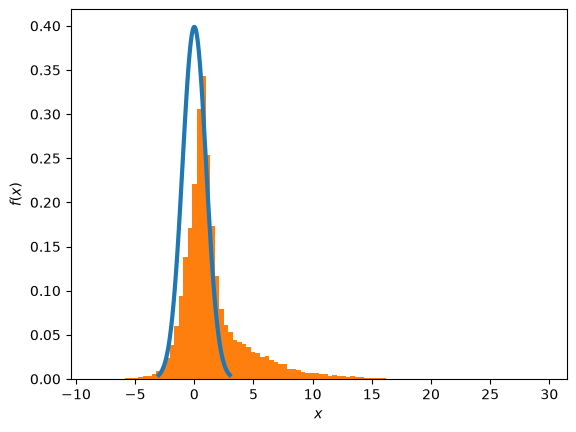

In [ ]:
tries = 10000

fisher_sample = Rvs.FISHER.value.distribution.rvs(tries, random_state=1)
t_sample = Rvs.STUDENT.value.distribution.rvs(tries, random_state=1)
chi_sample = Rvs.CHI.value.distribution.rvs(tries, random_state=1)
laplace_sample = Rvs.LAPLACE.value.distribution.rvs(tries, random_state=1)

sample = np.concatenate([fisher_sample, t_sample, chi_sample, laplace_sample])
sample


x = np.linspace(-3, 3, 100)
pdf = Rvs.NORMAL.value.distribution.pdf(x)

# плотность 
plt.plot(x, pdf, lw=3)

# гистограмма, параметр density отнормировал её. 
plt.hist(sample, bins=100, density=True);

plt.ylabel('$f(x)$')
plt.xlabel('$x$');

In [ ]:
rasp = Rvs.COUCHY.value
rv = rasp.distribution 
name = rasp.name
x1 = rasp.start
x2 = rasp.end
sample = rv.rvs(100, random_state=3)  # выборка

x = np.linspace(x1, x2, 100)

plt.title(f"Графики теоретической и эмпирической функции распределения")

# теоретическа cdf 
cdf = rv.cdf(x)
plt.plot(x, cdf, label='theoretical CDF')

# эмпирическая сdf
ecdf = ECDF(sample)
plt.step(ecdf.x, ecdf.y, label='empirical CDF')

plt.ylabel('$F(x)$')
plt.xlabel('$x$')
plt.legend(loc='upper left');

NameError: name 'Rvs' is not defined